## 4.1 뒤썩은 카드 덱에서 발깐색 카드 예측하기

### 기본 libray import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')
import unicodedata
import random
from common import *


plt.rcParams['font.family'] = "AppleGothic"  # 올바른 키
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 기호 깨짐 방지

In [2]:
# code 4-1 카드 덱 52장 모델링 하기
red_card   = 26 * [1]
black_card = 26 * [0]
unshuffled_deck = red_card + black_card

In [3]:
# code 4-2 카드 덱 52장 뒤섞기
np.random.seed(1)
shuffled_deck = np.random.permutation(unshuffled_deck)

In [4]:
# code 4-3 카드 전략 게임에 대한 코드
remaining_red_cards = 26
for i, card in enumerate(shuffled_deck[:-1]):
    remaining_red_cards -= card
    remaining_total_cards = 52 - i - 1
    if remaining_red_cards / remaining_total_cards > 0.5:
        break

print(f'{i} - 번째 인덱스에서 게임이 종료 되었습니다')
final_card = shuffled_deck[i +1]
color = 'red' if final_card else 0
print(f"카드 덱의 다음 카드는 {'빨간색' if final_card else '검은색'} 입니다")
print(f"{'이겼' if final_card else '졌'}습니다")

0 - 번째 인덱스에서 게임이 종료 되었습니다
카드 덱의 다음 카드는 빨간색 입니다
이겼습니다


In [5]:
# code 4-4 카드 게임 일반화하기
np.random.seed(0)
total_cards = 52
total_red_cards = 26

def execute_strategy(min_red_fraction=0.5, shuffled_deck=None, return_index = False):
    if shuffled_deck is None:
        shuffled_deck = np.random.permutation(unshuffled_deck)

    remaining_red_cards = total_red_cards

    for i, card in enumerate(shuffled_deck[:-1]):
        remaining_red_cards -= card
        fraction_red_cards = remaining_red_cards / (total_cards-i-1)
        if fraction_red_cards > min_red_fraction:
            break

    return (i + 1, shuffled_deck[ i + 1]) if return_index else shuffled_deck[i+1]

In [6]:
# code 4-5 1000번 이상 뒤섞기에 기본 전략 적용하기
observations = np.array([execute_strategy() for _ in range(1000)])

In [7]:
# code 4-6 이긴 빈도 계산하기
frequency_wins = observations.sum() / 1000
assert frequency_wins == observations.mean()
print(f"이긴 빈도는  {frequency_wins} 입니다")

이긴 빈도는  0.511 입니다


In [8]:
# code 4-7 총 수익 계산하기
dollars_won = frequency_wins * 1000
dollars_lost = (1 - frequency_wins) * 1000
total_profit = dollars_won - dollars_lost
print(f"총 수입은 ${total_profit:.2f} 입니다 ")

총 수입은 $22.00 입니다 


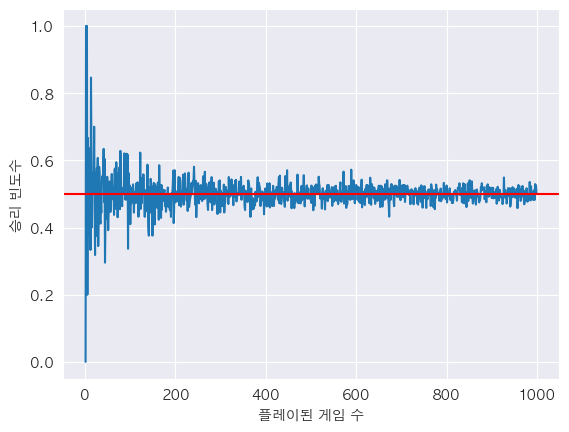

10,000번 뒤썩기로 얻은 이긴 빈도는 0.50 입니다


In [9]:
# code 4-8 시뮬레이션된 이긴 빈도 그래프 그리기
np.random.seed(0)
def repeat_game(number_repeats):
    observations = np.array([execute_strategy() for _ in range(number_repeats)])
    return observations.mean()

frequencies = []
for i in range(1,1000):
    frequencies.append(repeat_game(i))
plt.plot(list(range(1,1000)), frequencies)
plt.axhline(0.5, color='r')
plt.xlabel('플레이된 게임 수')
plt.ylabel('승리 빈도수')
plt.show()
print(f"10,000번 뒤썩기로 얻은 이긴 빈도는 {frequencies[-1]:.2f} 입니다")

In [11]:
# code 3-28 높은 신뢰 구간 계산하기
def compute_high_confidence_interval(likelihoods, bin_width):
    peak_index = likelihoods.argmax()
    area = likelihoods[peak_index] * bin_width
    start_index, end_index  = peak_index, peak_index + 1
    while area < 0.95:
        if start_index > 0:
            start_index -= 1
        if end_index < likelihoods.size-1:
            end_index += 1

        area = likelihoods[start_index : end_index+1].sum() * bin_width

    range_start, range_end = bin_edges[start_index], bin_edges[end_index]
    range_string = f"{range_start:.6f}-{range_end:.6f}"
    print((f"빈도 범위 {range_string} 는 {100 * area:.2f} % 신뢰 구간을 나타냅니다"))
    return start_index, end_index


빈도 범위 0.488938-0.509494 는 97.00 % 신뢰 구간을 나타냅니다


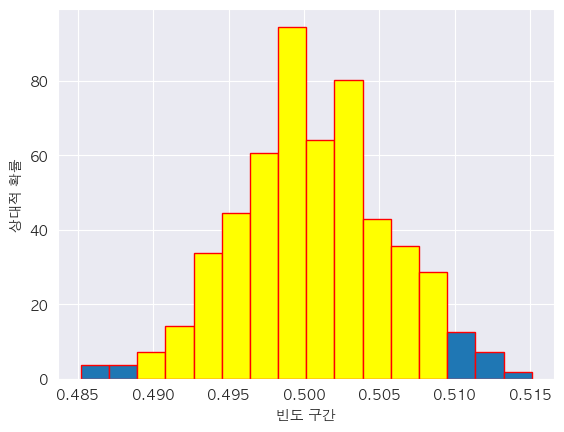

In [12]:
# code 4-9 뒤집기 300만 번에 대한 신뢰 구간 계산하기
np.random.seed(0)
frequency_array = np.array([repeat_game(10000) for _ in range(300)])

likelihoods, bin_edges, patches = plt.hist(frequency_array, bins='auto',
                                           edgecolor='red', density=True)
bin_width = bin_edges[1] - bin_edges[0]
start_index, end_index = compute_high_confidence_interval(likelihoods, bin_width)

for i in range(start_index, end_index):
    patches[i].set_facecolor('yellow')
plt.xlabel('빈도 구간')
plt.ylabel('상대적 확률')
plt.show()

In [27]:
# code 4-10 1억5,000번 뒤썩은 것에 대한 신뢰 구간 구하기
np.random.seed(0)
frequency_array = np.array([repeat_game(50000) for _ in range(3000)])
likelihoods, bin_edges,  = np.histogram(frequency_array, bins='auto', density=True)
bin_width = bin_edges[1] - bin_edges[0]
compute_high_confidence_interval(likelihoods, bin_width)

빈도 범위 0.495601-0.504345 는 96.03 % 신뢰 구간을 나타냅니다


(np.int64(11), np.int64(32))

In [29]:
# code 4-11 업데이트된 전략에 대한 신뢰 구간 계산하기
np.random.seed(0)
def repeat_game(number_repeats, min_red_fraction):
    observations = np.array([execute_strategy(min_red_fraction) for _ in range(number_repeats)])
    return observations.mean()

frequency_array = np.array([repeat_game(50000, 0.75) for _ in range(3000)])
likelihoods, bin_edges, = np.histogram(frequency_array, bins='auto', density=True)
bin_width = bin_edges[1] - bin_edges[0]
compute_high_confidence_interval(likelihoods, bin_width)

빈도 범위 0.495535-0.504344 는 96.43 % 신뢰 구간을 나타냅니다


(np.int64(9), np.int64(30))

## 4.2 열 장으로 구성된 카드 덱 하나에 대한 표본 공간으로 전략 최적화하기

In [13]:
# from 코드 1-5
def get_matching_event(event_condition, sample_space):
    return set([outcome for outcome in sample_space
                if event_condition(outcome)])

# from 코드 1-11
def compute_event_probability(event_condition, generic_sample_space):
    event = get_matching_event(event_condition, generic_sample_space)
    if type(generic_sample_space) == type(set()):
        return len(event) / len(generic_sample_space)

    event_size = sum(generic_sample_space[outcome]
                    for outcome in event)
    return event_size / sum(generic_sample_space.values())

In [14]:
# code 4-12 카드 덱 열 장에 기본 전략 적용하기
import itertools
total_cards = 10
total_red_cards = int(total_cards / 2)
total_black_cards = total_red_cards
unshuffled_deck = [1] * total_red_cards + [0] * total_black_cards
sample_space = set(itertools.permutations(unshuffled_deck))
win_condition = lambda x : execute_strategy(shuffled_deck=np.array(x))
prob_win = compute_event_probability(win_condition, sample_space)
print(f"승릴할 확률은 {prob_win} 입니다")

승릴할 확률은 0.5 입니다


In [15]:
# code 4-13 카드 덱 열 장에 여러 개의 전략 적응하기
def scan_strategies():
    fraction = [value / 100 for value in range(50, 100)]
    probabilities =  []
    for frac in fraction:
        win_condition = lambda x: execute_strategy(frac, shuffled_deck = np.array(x))
        probabilities.append(compute_high_confidence_interval(win_condition, sample_space))
    return probabilities

probabilities = scan_strategies()
print(f'승리할 가장 낮은 확율은 {min(probabilities):.2f} 입니다')
print(f'승리할 가장 높은 확율은 {max(probabilities):.2f} 입니다')

AttributeError: 'function' object has no attribute 'argmax'

In [16]:
def scan_strategies():
    fractions = [value / 100 for value in range(50, 100)]
    probabilities = []
    for frac in fractions:
        win_condition = lambda x: execute_strategy(frac, shuffled_deck=np.array(x))
        probabilities.append(compute_event_probability(win_condition, sample_space))
    return probabilities

probabilities = scan_strategies()
print(f"승리할 가장 낮은 확률은 {min(probabilities)} 입니다.")
print(f"승리할 가장 높은 확률은 {max(probabilities)} 입니다")

NameError: name 'scan_strategies' is not defined

In [ ]:
# code 4-14 여러 카드 덱에 여러 개의 적용하기
for total_cards in [2,4,6,8]:
    total_red_cards = int(total_cards / 2)
    total_black_cards = total_red_cards
    unshuffled_deck = [1] * total_red_cards + [0] * total_black_cards

    sample_space = set(itertools.permutations(unshuffled_deck))
    probabilities = scan_strategies()
    if all(prob == 0.5 for prob in probabilities):
        print(f'크리가 {total_cards}인 카드 덱에 대한 승리 전략은 발견되지 않았습니다')
    else:
        print(f'크리가 {total_cards}인 카드 덱에 대한 승리 전략이 발견되었습니다')